# MCA Aplicado a Banca Retail — Business Case Completo
## Segmentación de Clientes mediante Análisis de Correspondencias Múltiples (MCA)

> **Módulo Multivariado · Data Science for Business · FUTURA**

---

### El problema de negocio

Un banco retail quiere **segmentar su base de clientes** para diseñar campañas comerciales
diferenciadas. El problema: las variables más ricas del cliente **no son numéricas**, son
**categóricas**: el canal que prefiere, el producto que tiene, su nivel de riesgo, su rango de
edad... No podemos calcular "el promedio de App y Sucursal", ni correr un PCA sobre ellas.

> ❓ *"App" no es un número. ¿Cómo encontramos estructura, perfiles y asociaciones cuando todo
> son etiquetas?*

**MCA (Multiple Correspondence Analysis)** es la respuesta. Es el PCA de los datos categóricos:
toma decenas de tablas de contingencia cruzadas y las convierte en **un mapa 2D interpretable**
donde las categorías que "van juntas" quedan cerca y los perfiles opuestos quedan lejos.

### El objetivo de este caso

Demostrar que **MCA es, ante todo, una herramienta interpretativa**. No buscamos predecir; buscamos
*entender*. Al terminar tendremos:

| Entregable | Pregunta de negocio que responde |
|---|---|
| **Mapa de categorías** | ¿Qué atributos de cliente aparecen juntos? |
| **Inercia por dimensión + Benzécri** | ¿Cuánta estructura real hay y en cuántos ejes? |
| **Contribución por dimensión (CTR)** | ¿Qué categorías *definen* cada eje del negocio? |
| **Calidad de representación (cos²)** | ¿De qué categorías me puedo fiar en el mapa? |
| **Scores + clustering** | ¿Cuántos segmentos existen y cómo describirlos? |

---

In [ ]:
FAMD

---
## 0. Imports y configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import warnings
warnings.filterwarnings('ignore')

# ── Paleta corporativa FUTURA ────────────────────────────────────────────────
NAVY   = '#051C2C'   # header, matrices
TEAL   = '#00A9E0'   # Dimensión 1 / canal digital
GOLD   = '#B68A35'   # Dimensión 2 / valor
PURPLE = '#8E44AD'
GREEN  = '#2E933C'   # señal "buena" / dentro de umbral
RED    = '#C0392B'   # señal "trivial" / riesgo
ORANGE = '#E67E22'   # eigenvalores sin corregir
GREY   = '#7F8C8D'
# un color por variable categórica (8 variables)
VAR_COLORS = [TEAL, GOLD, PURPLE, GREEN, ORANGE, RED, '#16A085', NAVY]

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': '#CCCCCC', 'axes.grid': True, 'grid.color': '#EEEEEE',
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'font.size': 10,
    'axes.titlecolor': NAVY, 'figure.dpi': 110, 'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
})
sns.set_style('whitegrid')
np.random.seed(42)

FIGDIR = '.'   # las figuras se guardan junto al notebook
print('Entorno listo · paleta FUTURA cargada')

Entorno listo · paleta FUTURA cargada


---
## 1. Generación del Dataset Bancario Categórico

Simulamos **9.000 clientes** de banca retail descritos por **8 variables categóricas**. Cada
cliente proviene (de forma latente y *oculta para el análisis*) de uno de **4 segmentos reales**.
Esta verdad-de-terreno NO se usa en el MCA — la guardamos aparte para, al final, comprobar si MCA
fue capaz de **redescubrir** la estructura sin conocerla.

**Las 8 variables (Q = 8):**

| Variable | Categorías |
|---|---|
| `Edad` | Joven · Adulto · Senior |
| `Canal` | App · Web · Sucursal · CallCenter |
| `Tarjeta` | SinTarjeta · Clasica · Premium |
| `Ingreso` | Bajo · Medio · Alto |
| `FrecDigital` | Nula · Baja · Media · Alta |
| `Producto` | Ahorro · Credito · Hipoteca · Inversion |
| `Antiguedad` | Nuevo · Establecido · Leal |
| `Riesgo` | RiesgoBajo · RiesgoMedio · RiesgoAlto |

Cada segmento tiene una **distribución de probabilidad propia** sobre cada variable (no categorías
fijas): así obtenemos datos realistas, con ruido y solapamiento, no un patrón perfecto de juguete.

---
## 2. Análisis Exploratorio Categórico (EDA)

Antes del MCA, miramos la **distribución de cada variable**. En datos categóricos el EDA no es de
medias y desviaciones, sino de **frecuencias**: ¿qué tan común es cada categoría? Esto importa
porque MCA pondera por la **masa** (frecuencia) de cada categoría — las categorías raras se
comportan distinto a las frecuentes.

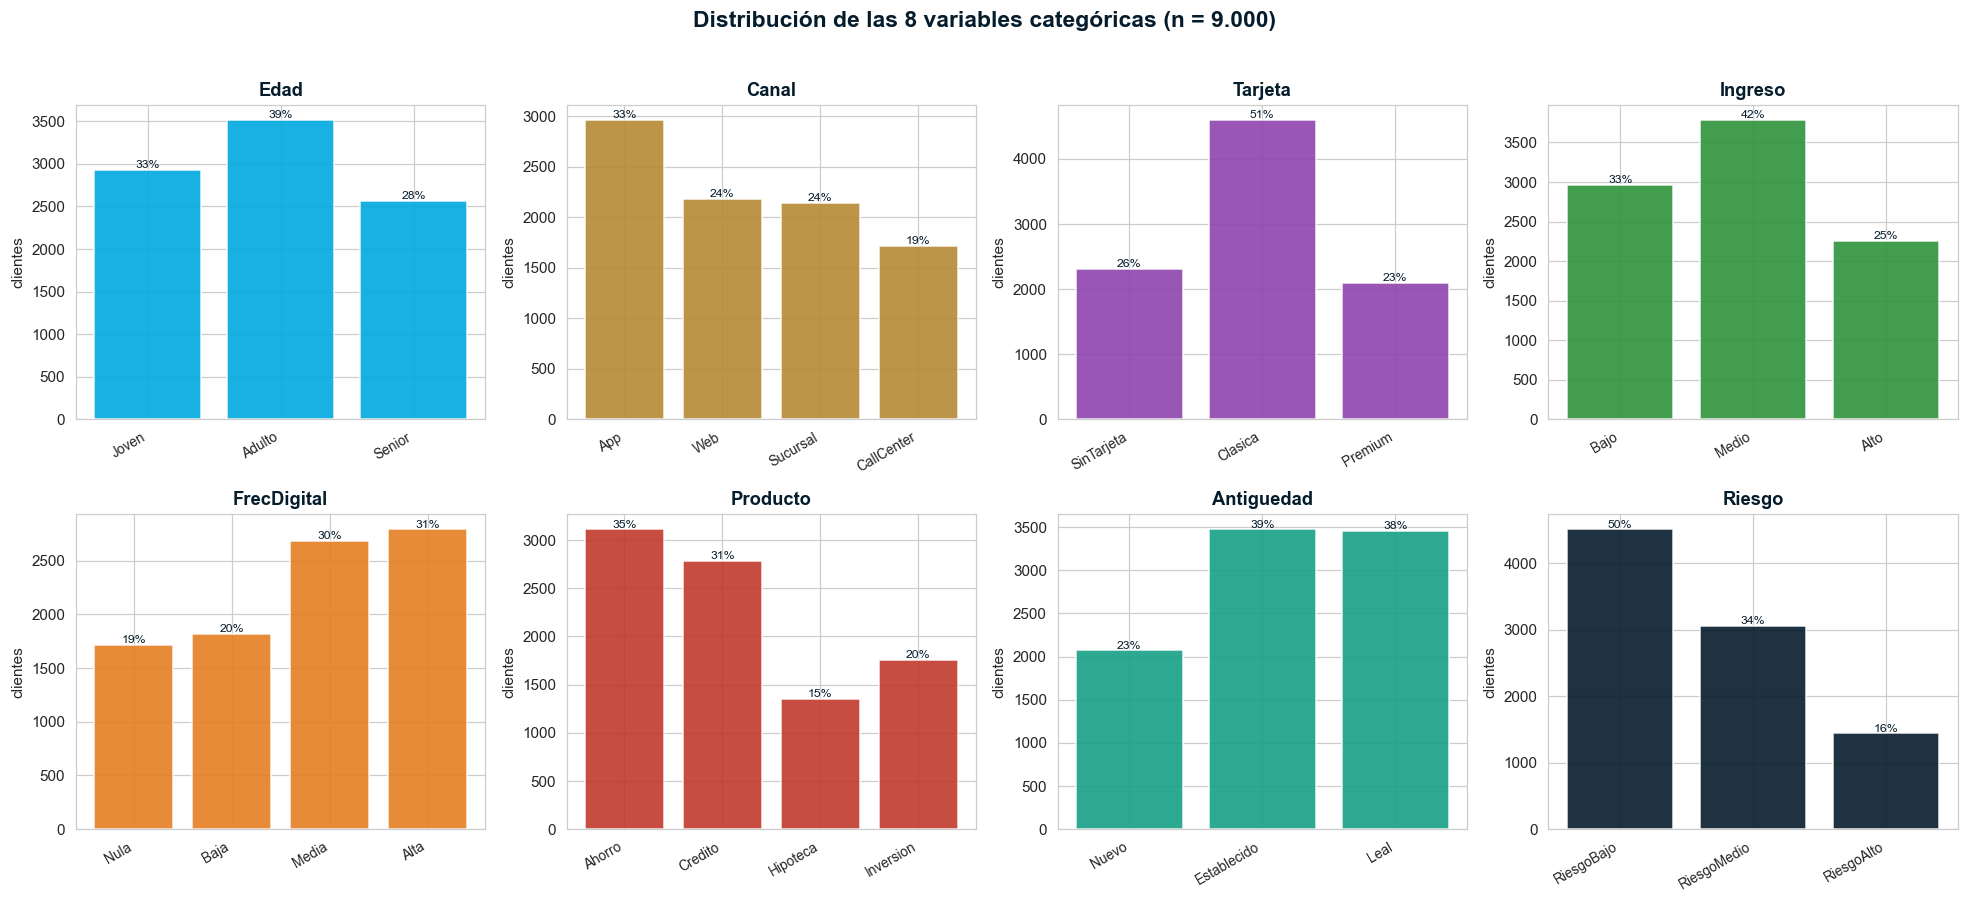

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (var, cats) in zip(axes.ravel(), variables.items()):
    vc = df[var].value_counts().reindex(cats)
    bars = ax.bar(range(len(cats)), vc.values, color=VAR_COLORS[list(variables).index(var)],
                  edgecolor='white', alpha=0.9)
    ax.set_title(var, fontsize=12)
    ax.set_xticks(range(len(cats)))
    ax.set_xticklabels(cats, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel('clientes')
    for b, v in zip(bars, vc.values):
        ax.text(b.get_x()+b.get_width()/2, v, f'{v/N*100:.0f}%',
                ha='center', va='bottom', fontsize=8, color=NAVY)
fig.suptitle('Distribución de las 8 variables categóricas (n = 9.000)',
             fontsize=15, fontweight='bold', color=NAVY, y=1.02)
plt.tight_layout()
plt.savefig(f'{FIGDIR}/01_distribuciones_categoricas.png', dpi=130)
plt.show()

### 2.1 ¿Hay asociación entre las variables? — Test χ² de independencia

El análogo categórico al **test de esfericidad de Bartlett** del PCA. Antes de hacer MCA debemos
confirmar que las variables **no son independientes** entre sí: si lo fueran, no habría estructura
que mapear (todas las categorías caerían en el origen).

Para cada par de variables calculamos la **prueba χ² de independencia** y la **V de Cramér**
(intensidad de asociación, 0 = independencia, 1 = asociación perfecta):

$$V = \sqrt{\frac{\chi^2 / n}{\min(filas-1,\ columnas-1)}}$$

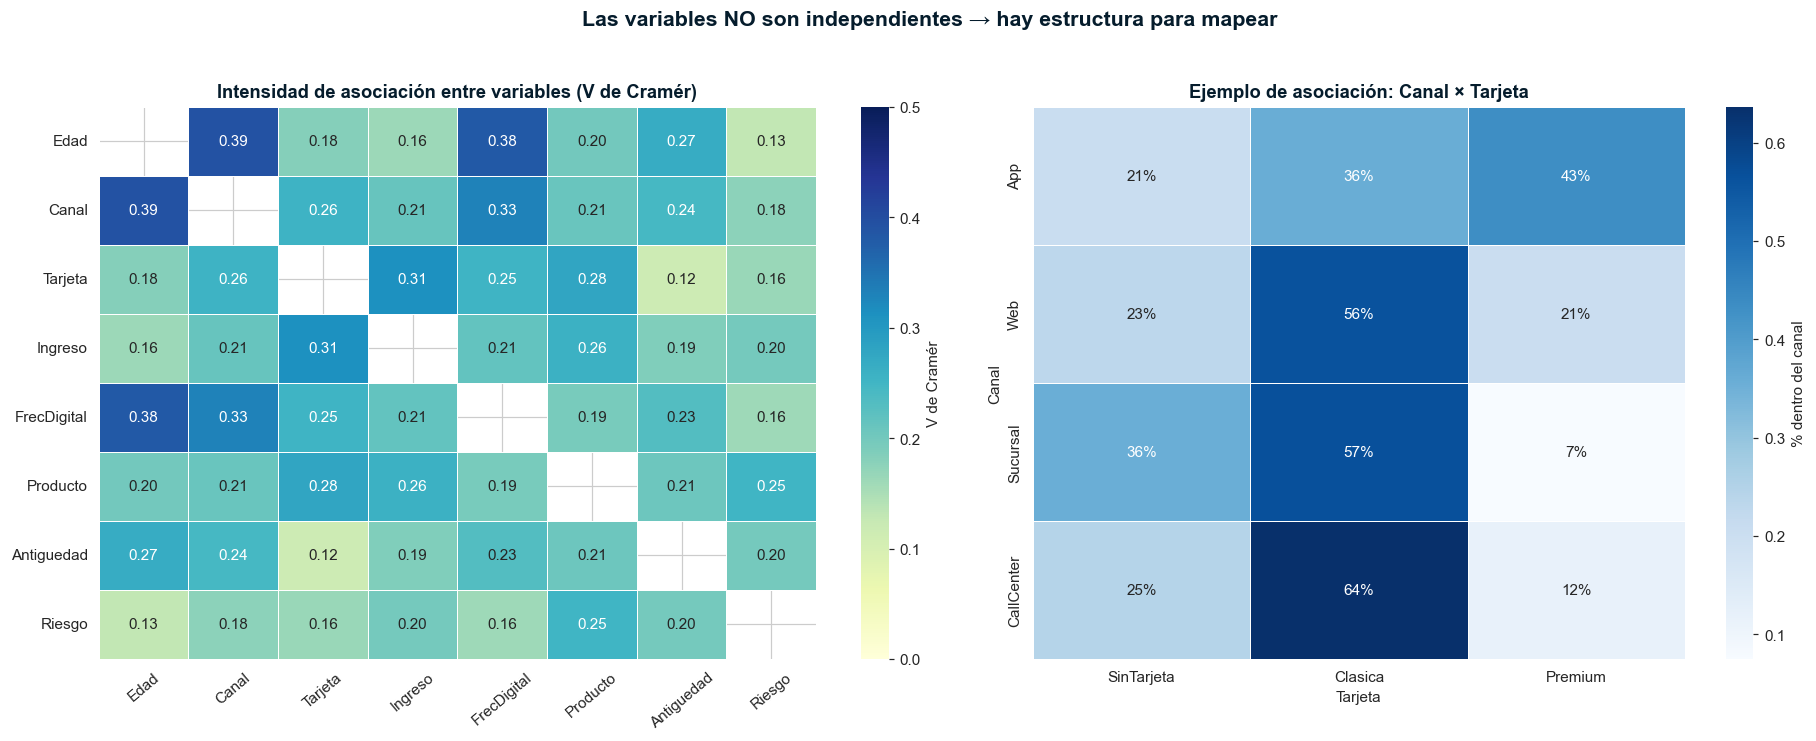

Pares de variables con asociación significativa (p<0.05): 28 de 28
V de Cramér media: 0.227  (App↔Sucursal y Premium↔Alto son los más asociados)


In [5]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(ct)
    n = ct.values.sum()
    k = min(ct.shape) - 1
    return np.sqrt((chi2 / n) / k), p

vnames = list(variables)
V = np.zeros((len(vnames), len(vnames)))
Pmat = np.ones((len(vnames), len(vnames)))
for i, a in enumerate(vnames):
    for j, b in enumerate(vnames):
        if i < j:
            v, p = cramers_v(df[a], df[b])
            V[i, j] = V[j, i] = v
            Pmat[i, j] = Pmat[j, i] = p
np.fill_diagonal(V, np.nan)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5),
                               gridspec_kw={'width_ratios':[1.1, 1]})
sns.heatmap(V, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=0.5,
            xticklabels=vnames, yticklabels=vnames, ax=ax1,
            cbar_kws={'label':"V de Cramér"}, linewidths=.5, linecolor='white')
ax1.set_title("Intensidad de asociación entre variables (V de Cramér)", fontsize=12)
ax1.tick_params(axis='x', rotation=40)

# tabla contingencia ejemplo: Canal × Tarjeta (proporciones por fila)
ct = pd.crosstab(df['Canal'], df['Tarjeta'], normalize='index')[['SinTarjeta','Clasica','Premium']]
sns.heatmap(ct, annot=True, fmt='.0%', cmap='Blues', ax=ax2,
            cbar_kws={'label':'% dentro del canal'}, linewidths=.5, linecolor='white')
ax2.set_title('Ejemplo de asociación: Canal × Tarjeta', fontsize=12)
ax2.set_xlabel('Tarjeta'); ax2.set_ylabel('Canal')

fig.suptitle('Las variables NO son independientes → hay estructura para mapear',
             fontsize=14, fontweight='bold', color=NAVY, y=1.03)
plt.tight_layout()
plt.savefig(f'{FIGDIR}/02_contingencia_chi2.png', dpi=130)
plt.show()

sig = (Pmat < 0.05)
np.fill_diagonal(sig, False)
n_pairs = len(vnames)*(len(vnames)-1)//2
print(f'Pares de variables con asociación significativa (p<0.05): '
      f'{int(sig.sum()/2)} de {n_pairs}')
print(f'V de Cramér media: {np.nanmean(V):.3f}  (App↔Sucursal y Premium↔Alto son los más asociados)')

---
## 3. Matriz Indicadora Z — codificando categorías como 0/1

MCA no opera sobre las etiquetas, sino sobre su **codificación disyuntiva completa** (one-hot):
cada categoría se convierte en una columna 0/1. Así, la variable `Edad` (3 categorías) genera 3
columnas, y un cliente "Joven" tiene `[1,0,0]`.

$$\mathbf{Z} \in \{0,1\}^{n \times J}, \qquad Z_{ij}=1 \text{ si el cliente } i \text{ está en la categoría } j$$

**Propiedad clave:** cada fila suma exactamente **Q = 8** (un 1 por variable). El total de columnas
es $J = \sum_q J_q = 27$.

In [ ]:
# edad  --- edad_joven   edad adulto   edad anciano
# joven        1              0              0
# adulo        0              1              0
# anciano      0              0              1

Z: 9000 filas × 27 columnas   ·   cada fila suma 8 (=Q)


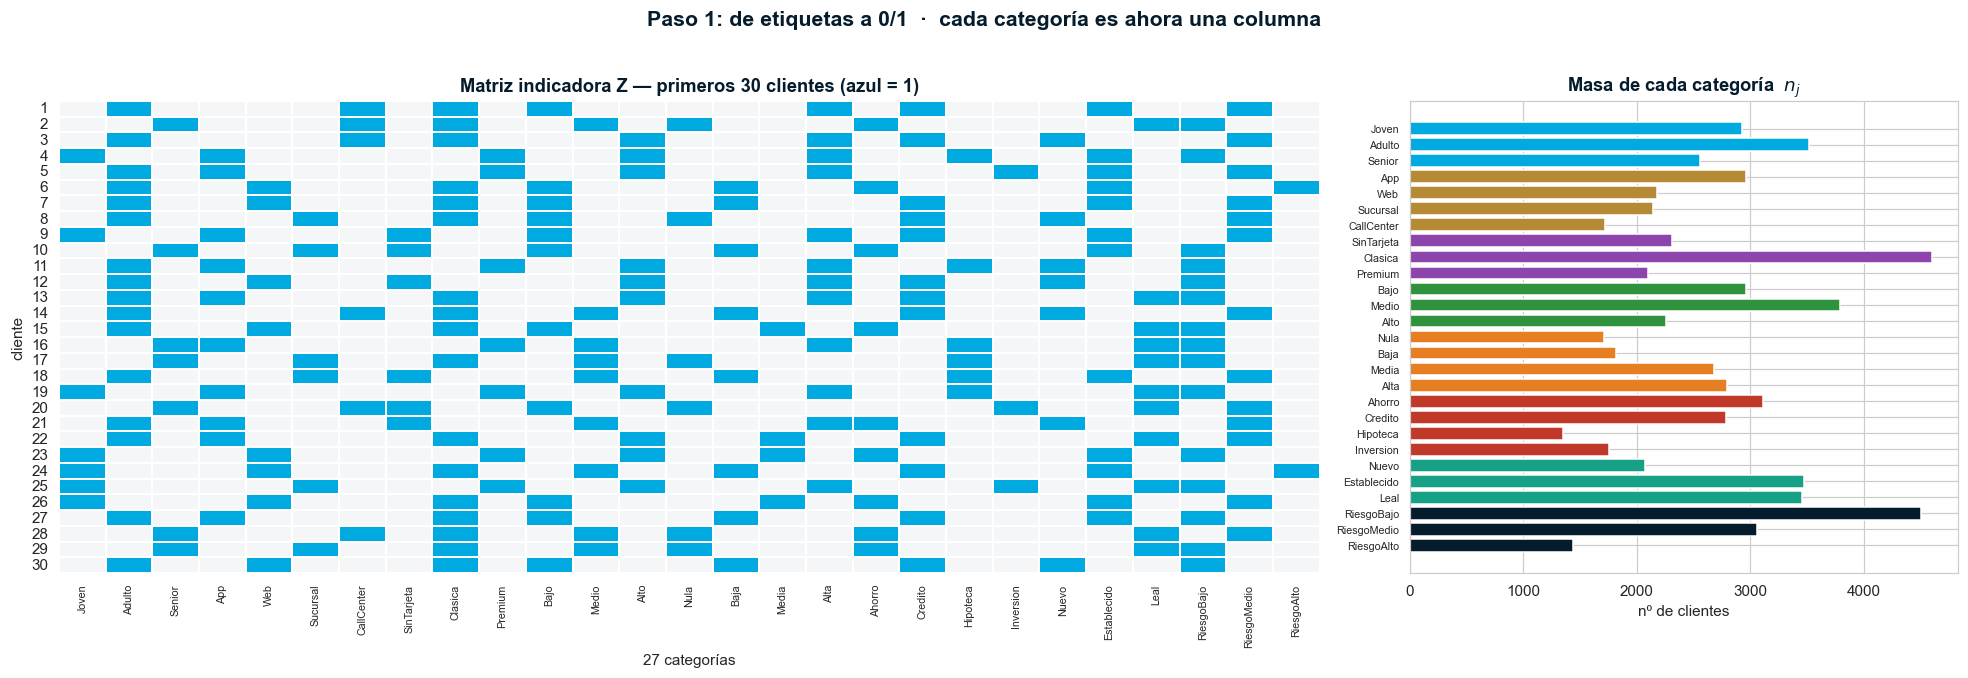

In [6]:
# Matriz indicadora con pandas (one-hot). Mantiene el orden de categorías definido arriba.
Z = pd.get_dummies(df, prefix_sep=' :: ')
# reordenar columnas en el orden natural variable→categoría
col_order = [f'{v} :: {c}' for v, cats in variables.items() for c in cats]
Z = Z[col_order].astype(float)
cats_full = Z.columns.tolist()                 # 27 etiquetas "Variable :: Categoria"
cat_var   = [c.split(' :: ')[0] for c in cats_full]   # variable de cada categoría
cat_lab   = [c.split(' :: ')[1] for c in cats_full]   # etiqueta corta

n, J = Z.shape
Q = df.shape[1]
print(f'Z: {n} filas × {J} columnas   ·   cada fila suma {int(Z.iloc[0].sum())} (=Q)')
assert (Z.sum(axis=1) == Q).all()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6),
                               gridspec_kw={'width_ratios':[2.3, 1]})
sns.heatmap(Z.iloc[:30].values, cmap=['#F4F6F7', TEAL], cbar=False, ax=ax1,
            linewidths=.3, linecolor='white',
            xticklabels=cat_lab, yticklabels=range(1,31))
ax1.set_title('Matriz indicadora Z — primeros 30 clientes (azul = 1)', fontsize=12)
ax1.set_xlabel('27 categorías'); ax1.set_ylabel('cliente')
ax1.tick_params(axis='x', rotation=90, labelsize=7)

nj = Z.sum(axis=0).values
colors_nj = [VAR_COLORS[list(variables).index(v)] for v in cat_var]
ax2.barh(range(J), nj, color=colors_nj, edgecolor='white')
ax2.set_yticks(range(J)); ax2.set_yticklabels(cat_lab, fontsize=7)
ax2.invert_yaxis()
ax2.set_title('Masa de cada categoría  $n_j$', fontsize=12)
ax2.set_xlabel('nº de clientes')
fig.suptitle('Paso 1: de etiquetas a 0/1  ·  cada categoría es ahora una columna',
             fontsize=14, fontweight='bold', color=NAVY, y=1.02)
plt.tight_layout()
plt.savefig(f'{FIGDIR}/03_matriz_indicadora.png', dpi=130)
plt.show()

---
## 4. Matriz de Burt — todas las tablas de contingencia a la vez

$$\mathbf{B} = \mathbf{Z}^\top \mathbf{Z} \in \mathbb{R}^{J\times J}$$

La matriz de Burt es el **corazón del MCA**: superpone, en un solo objeto, **todas las tablas de
contingencia cruzadas** entre las 8 variables.

- **Bloques diagonales** (8 bloques): conteos de cada variable consigo misma → diagonal con las masas $n_j$.
- **Bloques fuera de la diagonal**: la tabla de contingencia entre dos variables (p. ej. Canal×Producto).

En lugar de revisar $\binom{8}{2}=28$ tablas a mano, MCA las descompone todas juntas.

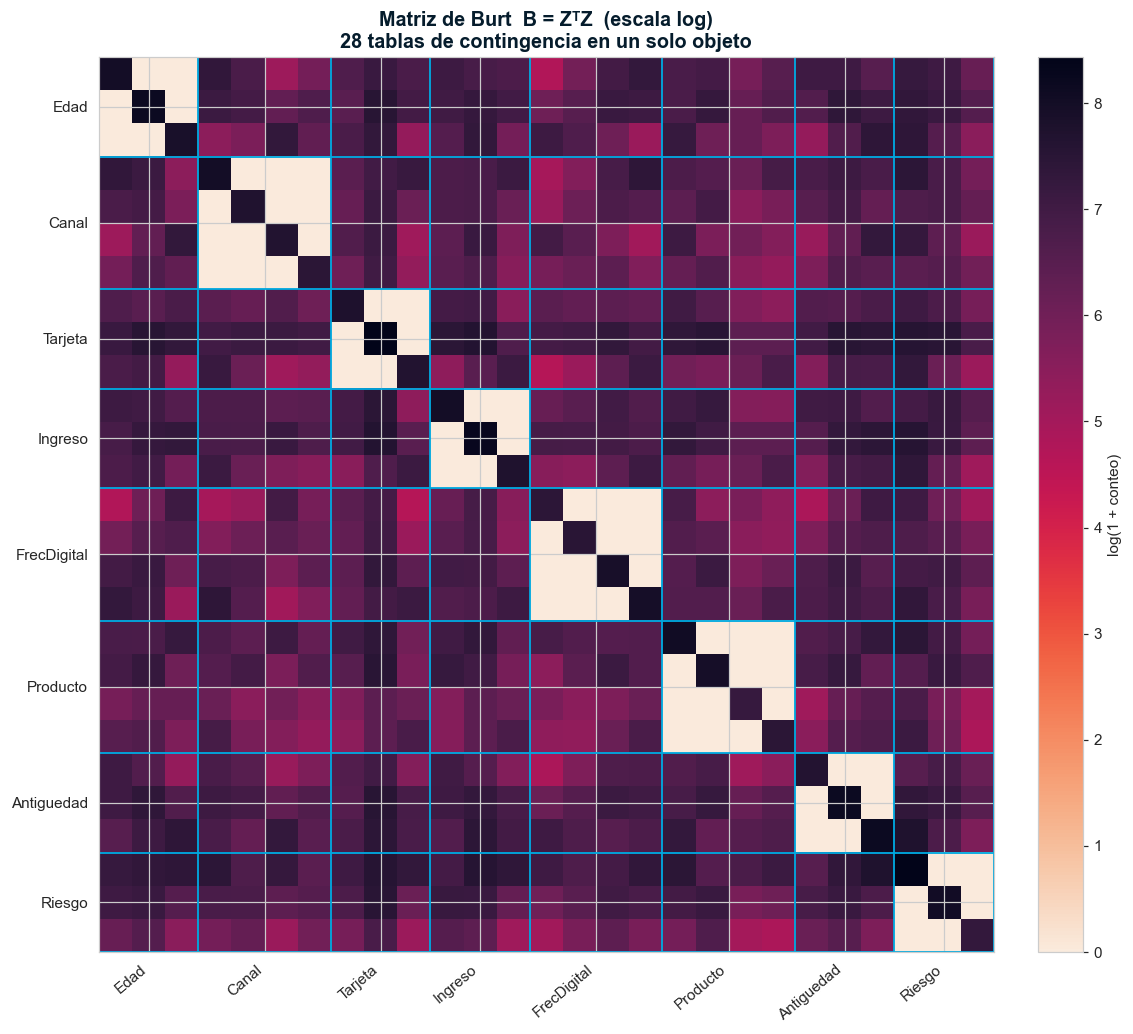

Diagonal de Burt = masas n_j (las mismas barras del paso anterior):
{'Joven': np.int64(2927), 'Adulto': np.int64(3515), 'Senior': np.int64(2558), 'App': np.int64(2964), 'Web': np.int64(2177), 'Sucursal': np.int64(2144)} ...


In [7]:
B = Z.T.values @ Z.values     # 27 × 27

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(np.log1p(B), cmap='rocket_r', aspect='equal')
# líneas separadoras de bloques (variables)
bounds = np.cumsum([0] + [len(c) for c in variables.values()])
for b in bounds:
    ax.axhline(b-0.5, color=TEAL, lw=1.2); ax.axvline(b-0.5, color=TEAL, lw=1.2)
# etiquetas de variable centradas en cada bloque
centers = (bounds[:-1] + bounds[1:]) / 2 - 0.5
ax.set_xticks(centers); ax.set_xticklabels(list(variables), rotation=40, ha='right', fontsize=10)
ax.set_yticks(centers); ax.set_yticklabels(list(variables), fontsize=10)
ax.set_title('Matriz de Burt  B = ZᵀZ  (escala log)\n28 tablas de contingencia en un solo objeto',
             fontsize=13)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='log(1 + conteo)')
plt.tight_layout()
plt.savefig(f'{FIGDIR}/04_matriz_burt.png', dpi=130)
plt.show()
print('Diagonal de Burt = masas n_j (las mismas barras del paso anterior):')
print(dict(zip(cat_lab[:6], np.diag(B)[:6].astype(int))), '...')

---
## 5. Cálculo del MCA

MCA es el **Análisis de Correspondencias de la matriz indicadora**. El procedimiento:

1. Matriz de correspondencias $\mathbf{P} = \mathbf{Z}/(nQ)$ y masas de fila $r_i$ y columna $c_j$.
2. Matriz de **residuos estandarizados** (sorpresa respecto a la independencia):
$$\mathbf{S} = \mathbf{D}_r^{-1/2}\,(\mathbf{P}-\mathbf{r}\mathbf{c}^\top)\,\mathbf{D}_c^{-1/2}$$
3. **SVD**: $\mathbf{S}=\mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^\top$. Las **inercias principales** son $\lambda_k=\sigma_k^2$.
4. Coordenadas principales:
$$\underbrace{\mathbf{G}=\mathbf{D}_c^{-1/2}\mathbf{V}\boldsymbol{\Sigma}}_{\text{categorías}},\qquad
  \underbrace{\mathbf{F}=\mathbf{D}_r^{-1/2}\mathbf{U}\boldsymbol{\Sigma}}_{\text{individuos}}$$

> 🔑 **Propiedad sorprendente:** la **inercia total** del MCA depende solo de la *estructura*, no de
> los datos:  $\;\text{Inercia} = \frac{J-Q}{Q} = \frac{27-8}{8} = 2{,}375$.  Lo que cambia con los
> datos es **cómo se reparte** esa inercia entre las dimensiones.

In [8]:
def mca(Z, Q):
    # MCA por SVD de la matriz indicadora. Devuelve coordenadas, inercias y diagnósticos.
    Zv = Z.values.astype(float)
    n, J = Zv.shape
    Ntot = n * Q
    P = Zv / Ntot
    r = P.sum(axis=1)                     # masas de fila  (= 1/n)
    c = P.sum(axis=0)                      # masas de columna (= n_j/(nQ))
    Dr_inv = 1/np.sqrt(r); Dc_inv = 1/np.sqrt(c)
    S = Dr_inv[:, None] * (P - np.outer(r, c)) * Dc_inv[None, :]
    U, sigma, Vt = np.linalg.svd(S, full_matrices=False)
    lam = sigma**2                        # inercias principales
    # nos quedamos con las dimensiones no triviales (rango = J - Q)
    keep = J - Q
    G = (Dc_inv[:, None] * Vt.T * sigma[None, :])[:, :keep]   # categorías (J × keep)
    F = (Dr_inv[:, None] * U   * sigma[None, :])[:, :keep]    # individuos (n × keep)
    lam = lam[:keep]; sigma = sigma[:keep]
    # corrección de Benzécri
    thr = 1.0/Q
    lam_b = np.where(lam > thr, (Q/(Q-1))**2 * (lam - thr)**2, 0.0)
    return dict(F=F, G=G, lam=lam, sigma=sigma, c=c, r=r,
                lam_b=lam_b, tot=lam.sum(), tot_b=lam_b.sum(), n=n, J=J, Q=Q)

R = mca(Z, Q)
lam, lam_b = R['lam'], R['lam_b']
G, F, c = R['G'], R['F'], R['c']

print(f'Inercia total observada : {R["tot"]:.4f}')
print(f'Inercia total teórica   : (J-Q)/Q = {(J-Q)/Q:.4f}   ✔')
print(f'\nInercia por dimensión (primeras 6):')
ve  = lam / lam.sum()
veb = lam_b / lam_b.sum()
for k in range(6):
    print(f'  Dim {k+1}: λ={lam[k]:.4f}  VE bruta={ve[k]*100:5.1f}%  '
          f'VE Benzécri={veb[k]*100:5.1f}%')

Inercia total observada : 2.3750
Inercia total teórica   : (J-Q)/Q = 2.3750   ✔

Inercia por dimensión (primeras 6):
  Dim 1: λ=0.3439  VE bruta= 14.5%  VE Benzécri= 58.6%
  Dim 2: λ=0.2996  VE bruta= 12.6%  VE Benzécri= 37.3%
  Dim 3: λ=0.1832  VE bruta=  7.7%  VE Benzécri=  4.1%
  Dim 4: λ=0.1265  VE bruta=  5.3%  VE Benzécri=  0.0%
  Dim 5: λ=0.1261  VE bruta=  5.3%  VE Benzécri=  0.0%
  Dim 6: λ=0.1245  VE bruta=  5.2%  VE Benzécri=  0.0%


### 5.1 Scree plot y la corrección de Benzécri — ¿cuánta estructura real hay?

Aquí aparece la **gran trampa del MCA**: las inercias "brutas" reparten la varianza entre muchísimas
dimensiones triviales (artefactos de la codificación 0/1), de modo que el % explicado por las
2 primeras dimensiones parece **decepcionantemente bajo** (~20-25%). En PCA eso sería un fracaso;
en MCA es **normal y engañoso**.

La **corrección de Benzécri** elimina la contribución trivial (solo cuenta dimensiones con
$\lambda_k > 1/Q$):

$$\tilde{\lambda}_k = \left(\tfrac{Q}{Q-1}\right)^2 \left(\lambda_k - \tfrac{1}{Q}\right)^2$$

Con la corrección, las mismas 2 dimensiones suelen explicar **70-90%** de la inercia *real*.
El mapa es idéntico; solo cambia el número que reportas. **Regla práctica: siempre reporta Benzécri.**

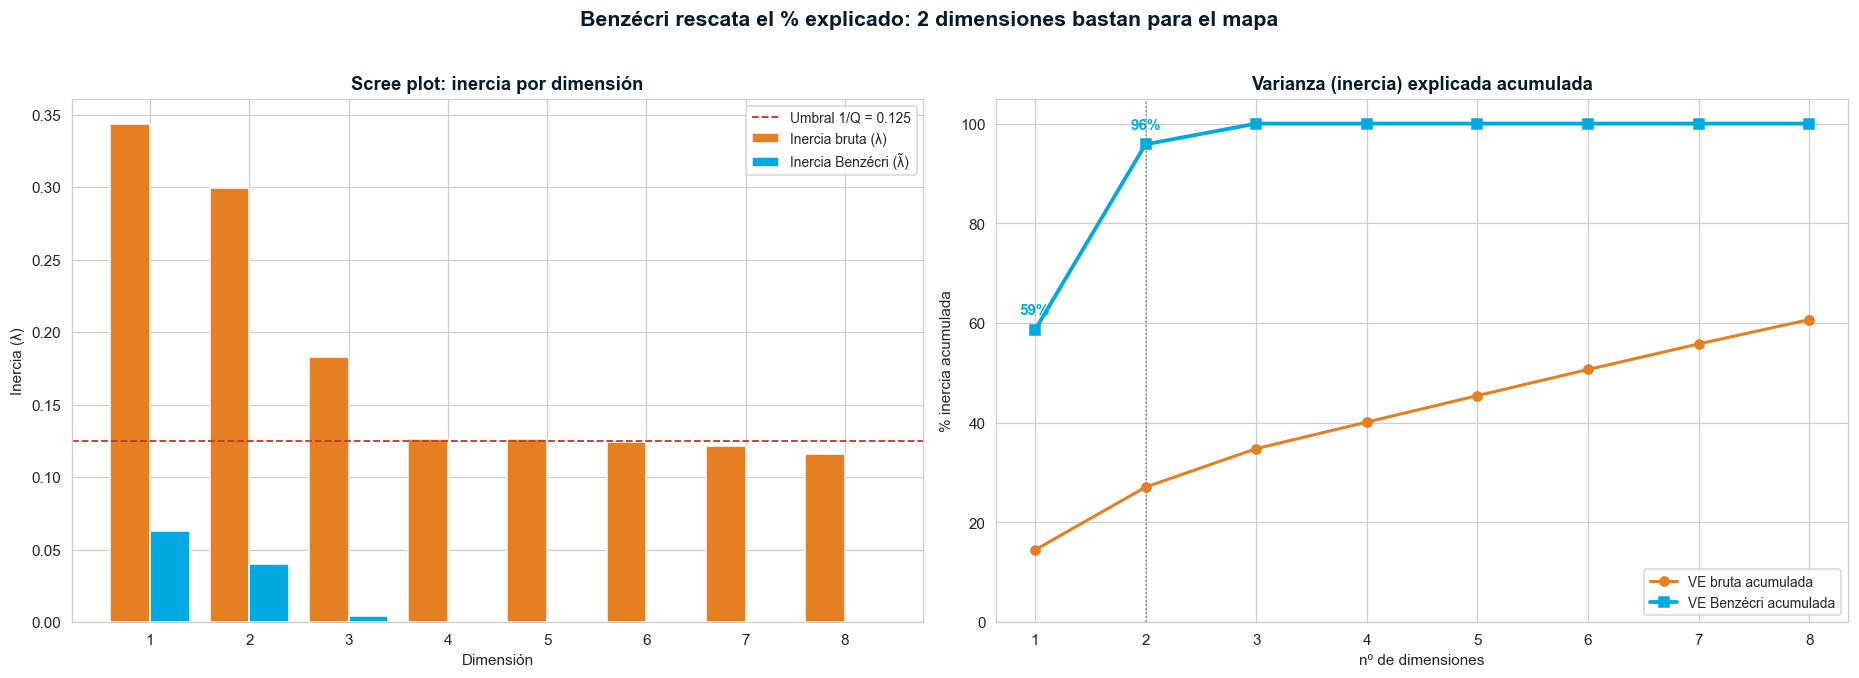

2 primeras dimensiones — VE bruta: 27.1%   →  VE Benzécri: 95.8%  (3.5× mayor)


In [9]:
nd = 8   # dimensiones a mostrar
x = np.arange(1, nd+1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6))

# --- izq: inercias brutas vs Benzécri ---
w = 0.4
ax1.bar(x - w/2, lam[:nd], w, label='Inercia bruta (λ)', color=ORANGE, edgecolor='white')
ax1.bar(x + w/2, lam_b[:nd], w, label='Inercia Benzécri (λ̃)', color=TEAL, edgecolor='white')
ax1.axhline(1/Q, color=RED, ls='--', lw=1.2, label=f'Umbral 1/Q = {1/Q:.3f}')
ax1.set_title('Scree plot: inercia por dimensión', fontsize=12)
ax1.set_xlabel('Dimensión'); ax1.set_ylabel('Inercia (λ)')
ax1.set_xticks(x); ax1.legend(fontsize=9)

# --- der: VE acumulada ---
ax2.plot(x, np.cumsum(ve[:nd])*100, 'o-', color=ORANGE, lw=2, label='VE bruta acumulada')
ax2.plot(x, np.cumsum(veb[:nd])*100, 's-', color=TEAL, lw=2.5, label='VE Benzécri acumulada')
for k in range(2):
    ax2.annotate(f'{np.cumsum(veb)[k]*100:.0f}%', (x[k], np.cumsum(veb[:nd])[k]*100),
                 textcoords='offset points', xytext=(0,10), ha='center',
                 fontsize=10, fontweight='bold', color=TEAL)
ax2.axvline(2, color=GREY, ls=':', lw=1)
ax2.set_title('Varianza (inercia) explicada acumulada', fontsize=12)
ax2.set_xlabel('nº de dimensiones'); ax2.set_ylabel('% inercia acumulada')
ax2.set_xticks(x); ax2.legend(fontsize=9); ax2.set_ylim(0, 105)

fig.suptitle('Benzécri rescata el % explicado: 2 dimensiones bastan para el mapa',
             fontsize=14, fontweight='bold', color=NAVY, y=1.02)
plt.tight_layout()
plt.savefig(f'{FIGDIR}/05_scree_benzecri.png', dpi=130)
plt.show()

print(f'2 primeras dimensiones — VE bruta: {np.cumsum(ve)[1]*100:.1f}%   '
      f'→  VE Benzécri: {np.cumsum(veb)[1]*100:.1f}%  ({np.cumsum(veb)[1]/np.cumsum(ve)[1]:.1f}× mayor)')

---
## 6. 🗺️ El Mapa de Categorías — la herramienta interpretativa central

Este es **el entregable estrella** del MCA. Proyectamos las 27 categorías en el plano de las
2 primeras dimensiones. **Cómo se lee:**

- **Proximidad** → dos categorías cercanas **coexisten** en los mismos clientes (p. ej. `App` y `Premium`).
- **Oposición por un eje** → categorías en extremos opuestos **casi nunca aparecen juntas**.
- **Distancia al origen** → categorías lejanas son **diagnósticas** (caracterizan perfiles
  específicos); las del centro son neutras/transversales.
- **Color** = variable de origen; el **tamaño** del punto refleja la masa $n_j$ (frecuencia).

Aquí dejamos de hablar de matemática y empezamos a **leer el negocio en un mapa**.

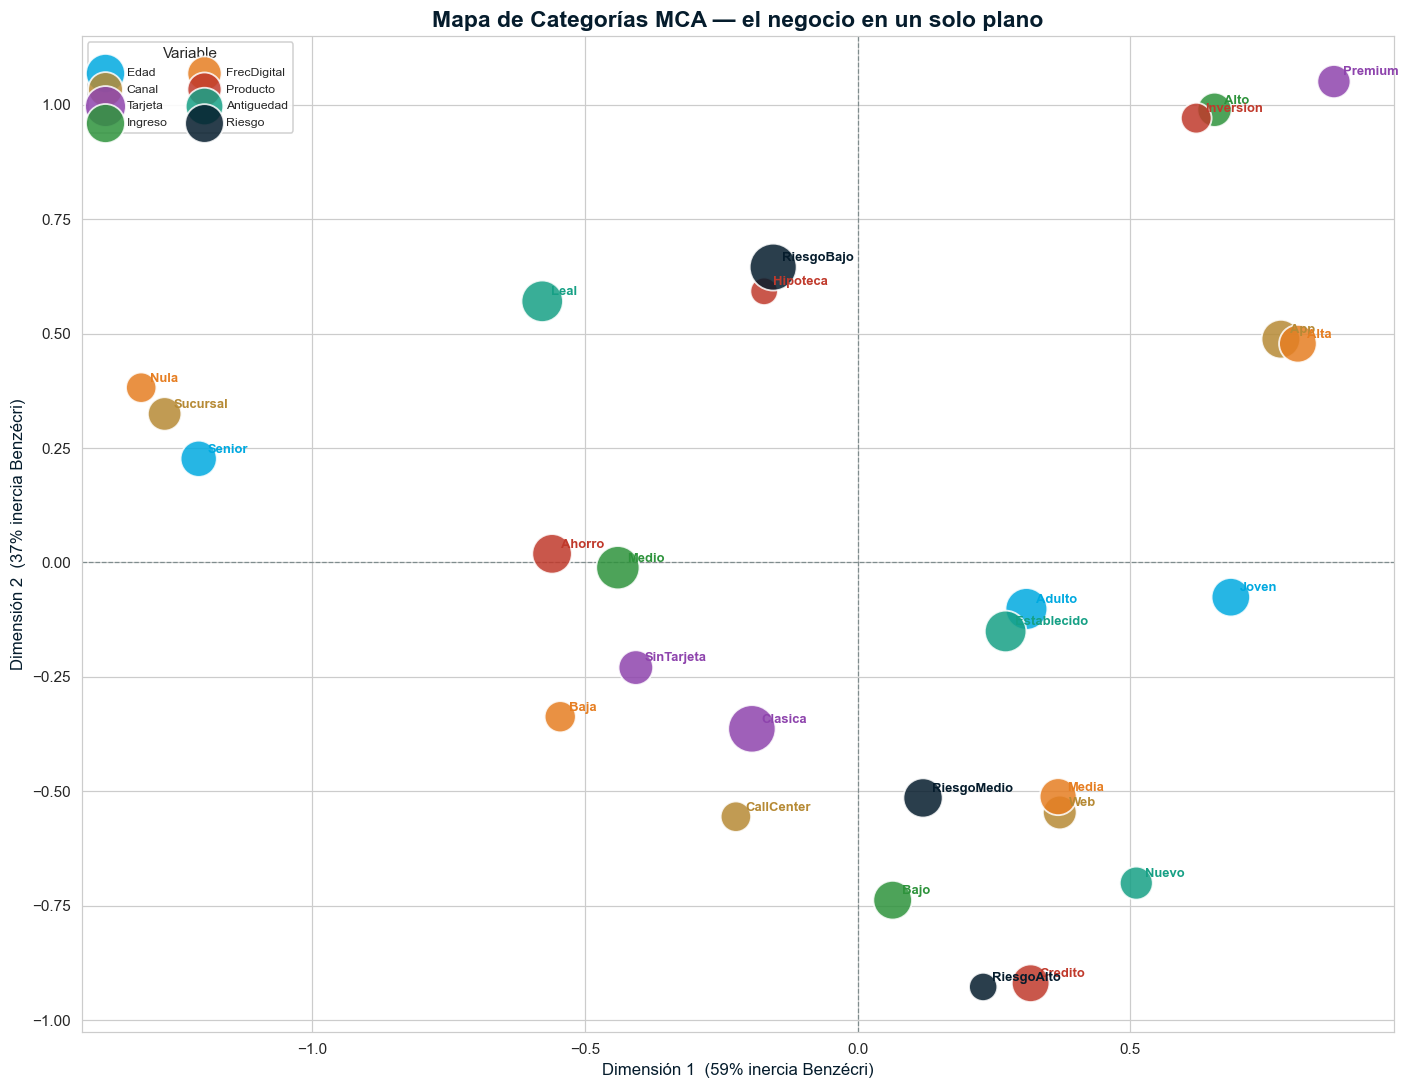

LECTURA DE LOS EJES (categorías extremas):

── Dimensión 1 ──
   (−) Nula, Sucursal, Senior, Leal
   (+) Premium, Alta, App, Joven
── Dimensión 2 ──
   (−) RiesgoAlto, Credito, Bajo, Nuevo
   (+) Premium, Alto, Inversion, RiesgoBajo


In [10]:
def lee_eje(dim, top=4):
    # Devuelve las categorías extremas (negativas y positivas) de una dimensión.
    coord = G[:, dim]
    order = np.argsort(coord)
    neg = [(cat_lab[i], cat_var[i], coord[i]) for i in order[:top]]
    pos = [(cat_lab[i], cat_var[i], coord[i]) for i in order[::-1][:top]]
    return neg, pos

def biplot_categorias(ax):
    for vi, var in enumerate(variables):
        idx = [i for i, v in enumerate(cat_var) if v == var]
        sizes = 60 + 900 * (R['c'][idx] / R['c'].max())
        ax.scatter(G[idx, 0], G[idx, 1], s=sizes, color=VAR_COLORS[vi],
                   alpha=0.85, edgecolor='white', linewidth=1.2, zorder=3, label=var)
        for i in idx:
            ax.annotate(cat_lab[i], (G[i, 0], G[i, 1]),
                        textcoords='offset points', xytext=(6, 4),
                        fontsize=8.5, fontweight='bold', color=VAR_COLORS[vi], zorder=4)
    ax.axhline(0, color=GREY, lw=0.8, ls='--'); ax.axvline(0, color=GREY, lw=0.8, ls='--')
    ax.set_xlabel(f'Dimensión 1  ({veb[0]*100:.0f}% inercia Benzécri)', fontsize=11, color=NAVY)
    ax.set_ylabel(f'Dimensión 2  ({veb[1]*100:.0f}% inercia Benzécri)', fontsize=11, color=NAVY)
    ax.legend(title='Variable', fontsize=8, ncol=2, loc='best', framealpha=0.9)

fig, ax = plt.subplots(figsize=(13, 10))
biplot_categorias(ax)
ax.set_title('Mapa de Categorías MCA — el negocio en un solo plano', fontsize=15)
plt.tight_layout()
plt.savefig(f'{FIGDIR}/06_mapa_categorias.png', dpi=140)
plt.show()

print('LECTURA DE LOS EJES (categorías extremas):\n')
for d in range(2):
    neg, pos = lee_eje(d)
    print(f'── Dimensión {d+1} ──')
    print('   (−) ' + ', '.join(f'{l}' for l, v, x in neg))
    print('   (+) ' + ', '.join(f'{l}' for l, v, x in pos))

---
## 7. Calidad de Representación (cos²) — ¿de qué categorías me puedo fiar?

El mapa de categorías vive en 2D, pero la estructura real tiene 19 dimensiones. Una categoría puede
estar **mal representada** en el plano 1-2 si su información "vive" en dimensiones superiores. Si la
interpretamos igual, **nos engañamos**.

El **coseno cuadrado (cos²)** mide qué fracción de la posición de una categoría queda capturada por
cada dimensión:

$$\cos^2_{jk} = \frac{G_{jk}^2}{\sum_m G_{jm}^2}$$

- $\cos^2_{j,1}+\cos^2_{j,2}$ alto (→ 1) = la categoría está **bien representada** en el mapa, interpretable con confianza.
- Suma baja (< 0.3) = la categoría está "escondida" en otros ejes → **no la sobreinterpretes**.

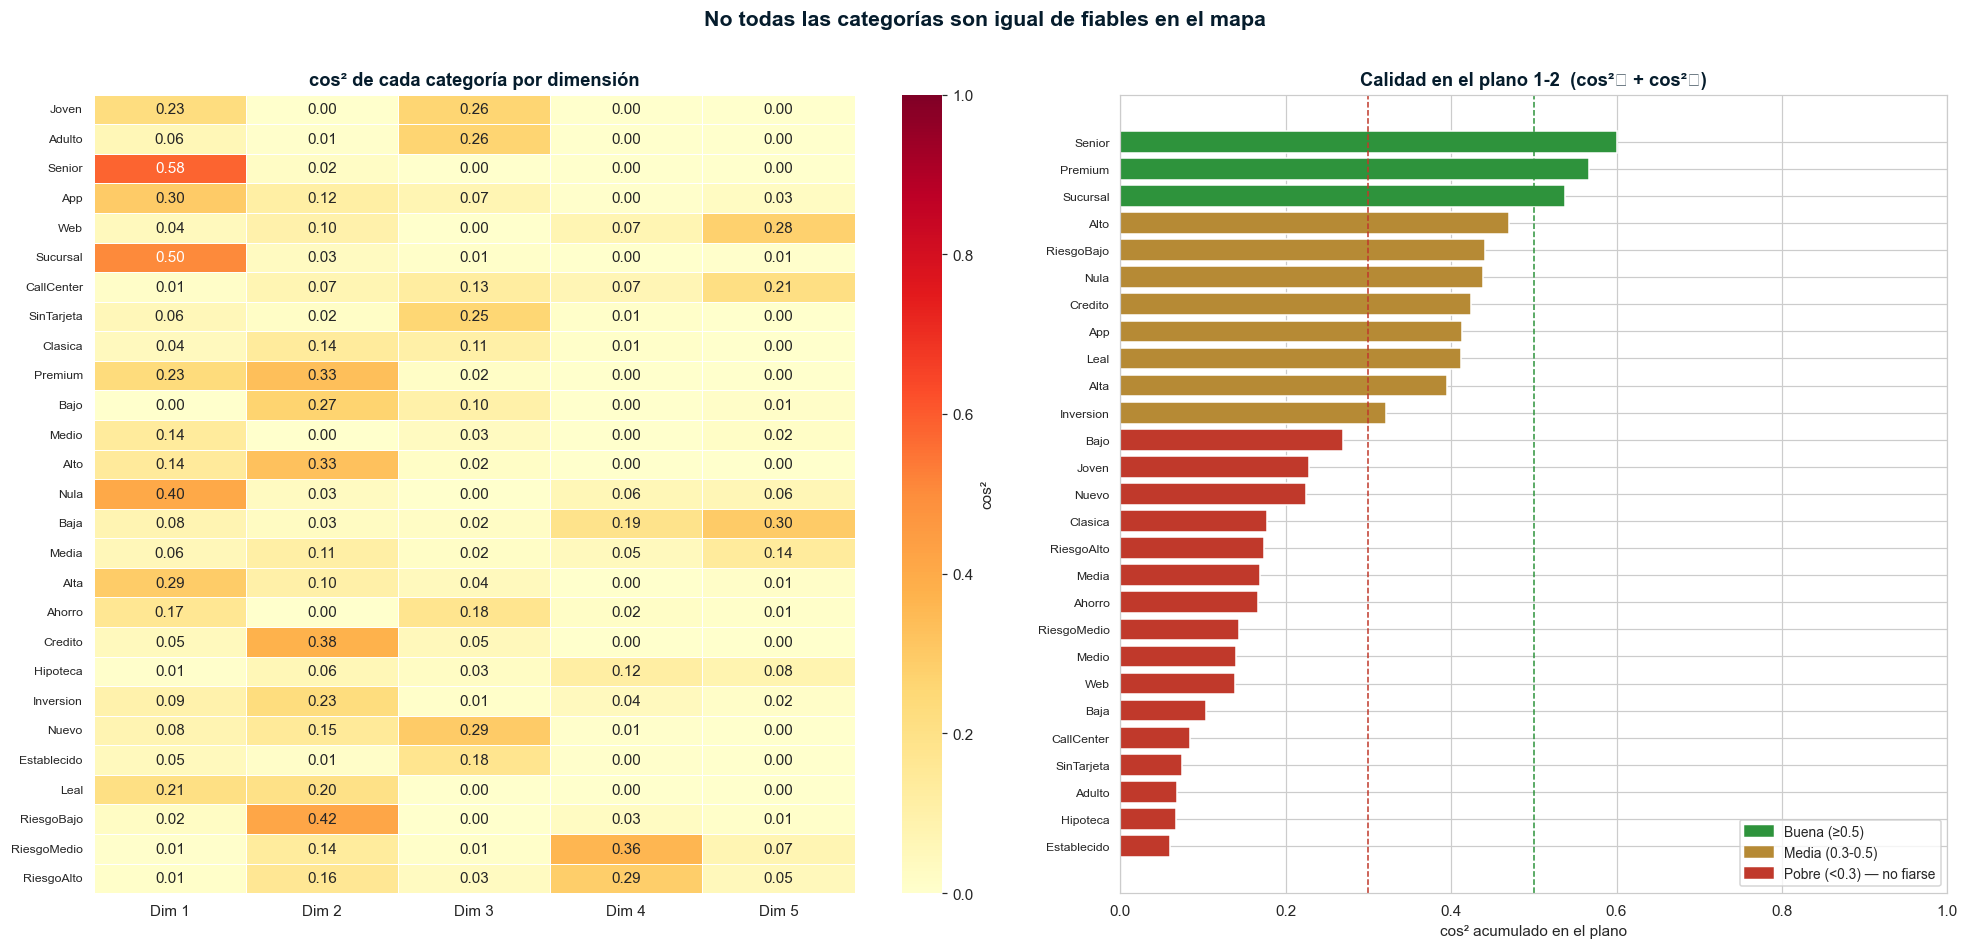

Bien representadas en el plano (3): Senior, Sucursal, Premium
Poco fiables en el plano (16): Joven, Adulto, Web, CallCenter, SinTarjeta, Clasica, Bajo, Medio, Baja, Media, Ahorro, Hipoteca, Nuevo, Establecido, RiesgoMedio, RiesgoAlto


In [11]:
# cos2 sobre TODAS las dimensiones retenidas
G2 = G**2
cos2 = G2 / G2.sum(axis=1, keepdims=True)        # J × keep
cos2_plane = cos2[:, 0] + cos2[:, 1]             # calidad en el plano 1-2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8.5),
                               gridspec_kw={'width_ratios':[1.15, 1]})

# heatmap cos2 (primeras 5 dims)
ndh = 5
sns.heatmap(cos2[:, :ndh], annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=1,
            yticklabels=cat_lab, xticklabels=[f'Dim {k+1}' for k in range(ndh)],
            ax=ax1, cbar_kws={'label':'cos²'}, linewidths=.5, linecolor='white')
ax1.set_title('cos² de cada categoría por dimensión', fontsize=12)
ax1.tick_params(axis='y', labelsize=8)

# barras: calidad en el plano 1-2, ordenadas
order = np.argsort(cos2_plane)
colors_q = [GREEN if cos2_plane[i] >= 0.5 else (GOLD if cos2_plane[i] >= 0.3 else RED)
            for i in order]
ax2.barh(range(J), cos2_plane[order], color=colors_q, edgecolor='white')
ax2.set_yticks(range(J)); ax2.set_yticklabels([cat_lab[i] for i in order], fontsize=8)
ax2.axvline(0.5, color=GREEN, ls='--', lw=1); ax2.axvline(0.3, color=RED, ls='--', lw=1)
ax2.set_title('Calidad en el plano 1-2  (cos²₁ + cos²₂)', fontsize=12)
ax2.set_xlabel('cos² acumulado en el plano'); ax2.set_xlim(0, 1)
leg = [Patch(color=GREEN, label='Buena (≥0.5)'), Patch(color=GOLD, label='Media (0.3-0.5)'),
       Patch(color=RED, label='Pobre (<0.3) — no fiarse')]
ax2.legend(handles=leg, fontsize=9, loc='lower right')

fig.suptitle('No todas las categorías son igual de fiables en el mapa',
             fontsize=14, fontweight='bold', color=NAVY, y=1.01)
plt.tight_layout()
plt.savefig(f'{FIGDIR}/07_cos2.png', dpi=130)
plt.show()

bien = [cat_lab[i] for i in range(J) if cos2_plane[i] >= 0.5]
mal  = [cat_lab[i] for i in range(J) if cos2_plane[i] < 0.3]
print(f'Bien representadas en el plano ({len(bien)}): {", ".join(bien)}')
print(f'Poco fiables en el plano ({len(mal)}): {", ".join(mal) if mal else "ninguna"}')

---
## 8. Contribución por Dimensión (CTR) — ¿qué categorías *definen* cada eje?

El cos² mira cada categoría por separado; la **contribución (CTR)** hace lo inverso: para una
dimensión dada, ¿qué categorías la **construyen**? Es lo que nos permite **dar nombre de negocio**
a cada eje.

$$\text{CTR}_{jk} = \frac{c_j\, G_{jk}^2}{\lambda_k}, \qquad \sum_j \text{CTR}_{jk}=1$$

Una categoría con CTR alta "tira" del eje hacia su lado. Comparamos contra la contribución media
$1/J = 1/27 = 3{,}7\%$: por encima de esa línea, la categoría es **definitoria** del eje.

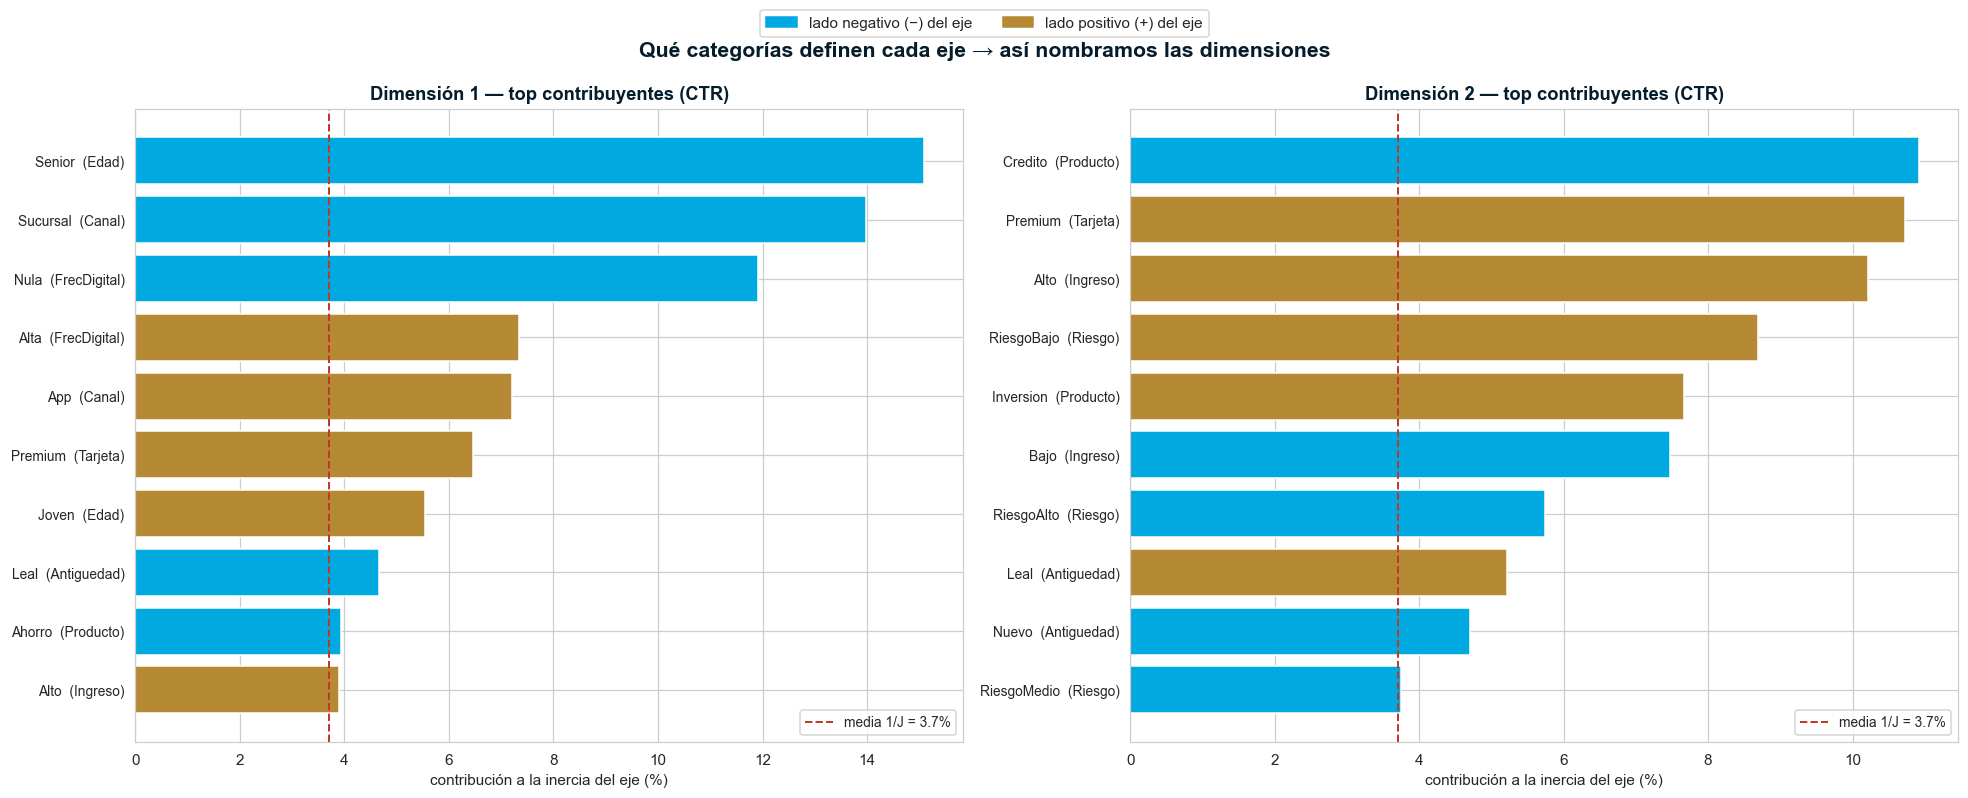

Dim 1 definida por: Senior(15%), Sucursal(14%), Nula(12%), Alta(7%), App(7%), Premium(6%)
Dim 2 definida por: Credito(11%), Premium(11%), Alto(10%), RiesgoBajo(9%), Inversion(8%), Bajo(7%)


In [12]:
CTR = (R['c'][:, None] * G2) / lam[None, :]      # J × keep, cada columna suma 1
avg = 1.0 / J

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for d, ax in enumerate(axes):
    ctr_d = CTR[:, d]
    order = np.argsort(ctr_d)[::-1][:10]          # top-10 contribuyentes
    signs = np.sign(G[order, d])
    colors = [TEAL if s < 0 else GOLD for s in signs]   # lado del eje
    bars = ax.barh(range(len(order)), ctr_d[order]*100, color=colors, edgecolor='white')
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([f'{cat_lab[i]}  ({cat_var[i]})' for i in order], fontsize=9)
    ax.invert_yaxis()
    ax.axvline(avg*100, color=RED, ls='--', lw=1.3, label=f'media 1/J = {avg*100:.1f}%')
    ax.set_title(f'Dimensión {d+1} — top contribuyentes (CTR)', fontsize=12)
    ax.set_xlabel('contribución a la inercia del eje (%)')
    ax.legend(fontsize=9)
leg = [Patch(color=TEAL, label='lado negativo (−) del eje'),
       Patch(color=GOLD, label='lado positivo (+) del eje')]
fig.legend(handles=leg, loc='upper center', ncol=2, fontsize=10, bbox_to_anchor=(0.5, 1.04))
fig.suptitle('Qué categorías definen cada eje → así nombramos las dimensiones',
             fontsize=14, fontweight='bold', color=NAVY, y=0.99)
plt.tight_layout()
plt.savefig(f'{FIGDIR}/08_contribuciones_dim.png', dpi=130)
plt.show()

for d in range(2):
    top = np.argsort(CTR[:, d])[::-1][:6]
    print(f'Dim {d+1} definida por: ' +
          ', '.join(f'{cat_lab[i]}({CTR[i,d]*100:.0f}%)' for i in top))

---
## 9. Scores de Individuos — proyectando a los 9.000 clientes

Las coordenadas de los individuos ($\mathbf{F}$) sitúan a **cada cliente** en el mismo mapa. Por la
**fórmula baricéntrica**, un cliente se ubica en el **promedio de las posiciones de sus categorías**:
si tiene `App + Premium + Alto`, caerá cerca de esa zona del mapa.

Superponemos los 9.000 clientes (puntos pequeños) con las 27 categorías (puntos grandes): así vemos
**dónde se concentran los perfiles** y qué atributos los caracterizan. *(Coloreamos por el segmento
real solo para validar visualmente — el MCA nunca lo vio.)*

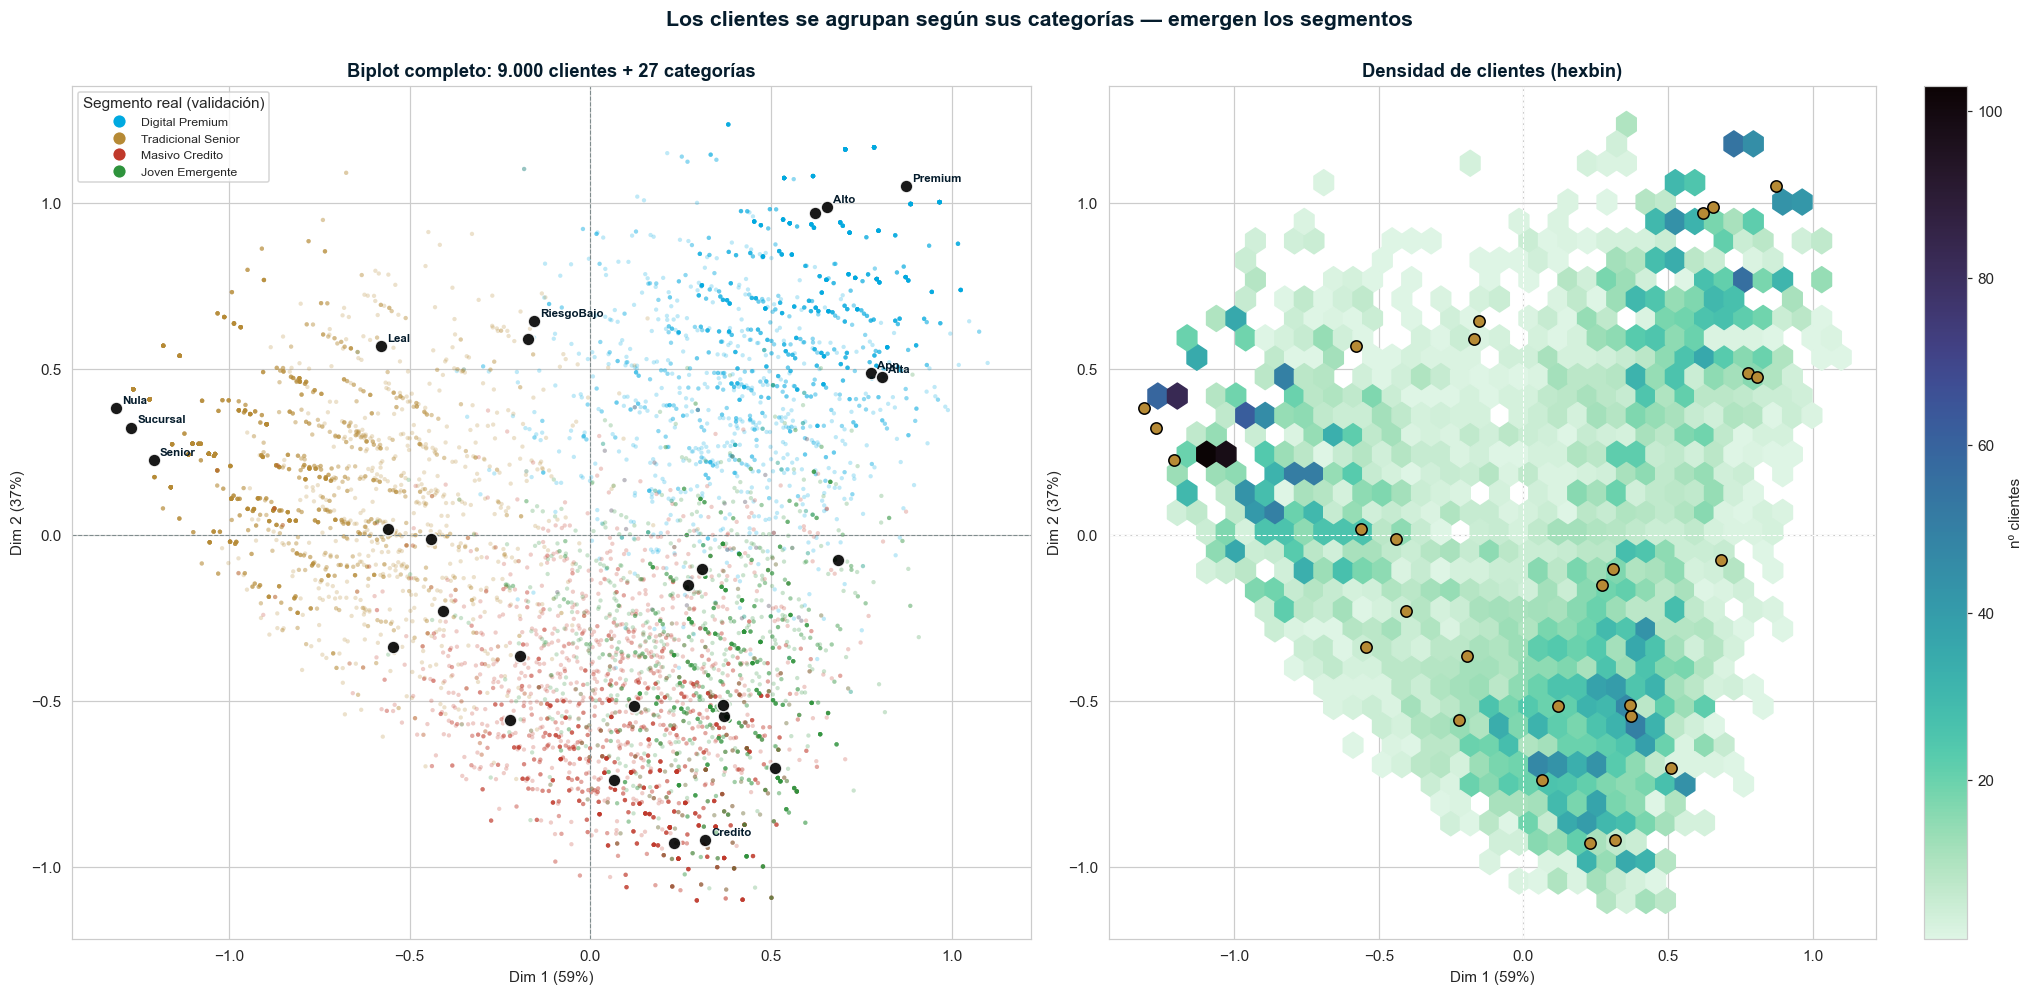

In [13]:
seg_palette = {'Digital Premium': TEAL, 'Tradicional Senior': GOLD,
               'Masivo Credito': RED, 'Joven Emergente': GREEN}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(19, 9))

# izq: nube de clientes coloreada por segmento real + categorías encima
for seg, col in seg_palette.items():
    m = (segmento_real.values == seg)
    ax1.scatter(F[m, 0], F[m, 1], s=8, color=col, alpha=0.25, edgecolor='none')
for vi, var in enumerate(variables):
    idx = [i for i, v in enumerate(cat_var) if v == var]
    ax1.scatter(G[idx, 0], G[idx, 1], s=70, color='black', alpha=0.9, zorder=5,
                marker='o', edgecolor='white', linewidth=1)
for i in range(J):
    if cos2_plane[i] >= 0.35:    # solo etiquetamos las bien representadas
        ax1.annotate(cat_lab[i], (G[i, 0], G[i, 1]), fontsize=7.5, fontweight='bold',
                     color=NAVY, zorder=6, textcoords='offset points', xytext=(4,3))
ax1.axhline(0, color=GREY, lw=0.7, ls='--'); ax1.axvline(0, color=GREY, lw=0.7, ls='--')
ax1.set_title('Biplot completo: 9.000 clientes + 27 categorías', fontsize=12)
ax1.set_xlabel(f'Dim 1 ({veb[0]*100:.0f}%)'); ax1.set_ylabel(f'Dim 2 ({veb[1]*100:.0f}%)')
leg = [Line2D([0],[0], marker='o', color='w', markerfacecolor=col, markersize=9, label=seg)
       for seg, col in seg_palette.items()]
ax1.legend(handles=leg, title='Segmento real (validación)', fontsize=8, loc='best')

# der: densidad por hexbin de la nube de clientes
hb = ax2.hexbin(F[:, 0], F[:, 1], gridsize=35, cmap='mako_r', mincnt=1)
ax2.scatter(G[:, 0], G[:, 1], s=55, color=GOLD, edgecolor='black', zorder=5)
ax2.axhline(0, color='white', lw=0.7, ls='--'); ax2.axvline(0, color='white', lw=0.7, ls='--')
ax2.set_title('Densidad de clientes (hexbin)', fontsize=12)
ax2.set_xlabel(f'Dim 1 ({veb[0]*100:.0f}%)'); ax2.set_ylabel(f'Dim 2 ({veb[1]*100:.0f}%)')
plt.colorbar(hb, ax=ax2, label='nº clientes')

fig.suptitle('Los clientes se agrupan según sus categorías — emergen los segmentos',
             fontsize=14, fontweight='bold', color=NAVY, y=1.00)
plt.tight_layout()
plt.savefig(f'{FIGDIR}/09_biplot_completo.png', dpi=130)
plt.show()

---
## 10. Segmentación: K-means sobre las dimensiones MCA

MCA convirtió categorías en **coordenadas numéricas** (las dimensiones). Sobre ellas ya **sí**
podemos aplicar algoritmos numéricos como **K-means**. Usamos las primeras 5 dimensiones (las que
concentran la inercia) y buscamos 4 grupos.

La gran ventaja sobre clusterizar las categorías crudas: el resultado es **interpretable** — cada
cluster se describe por su posición en el mapa y por las categorías que tiene cerca.

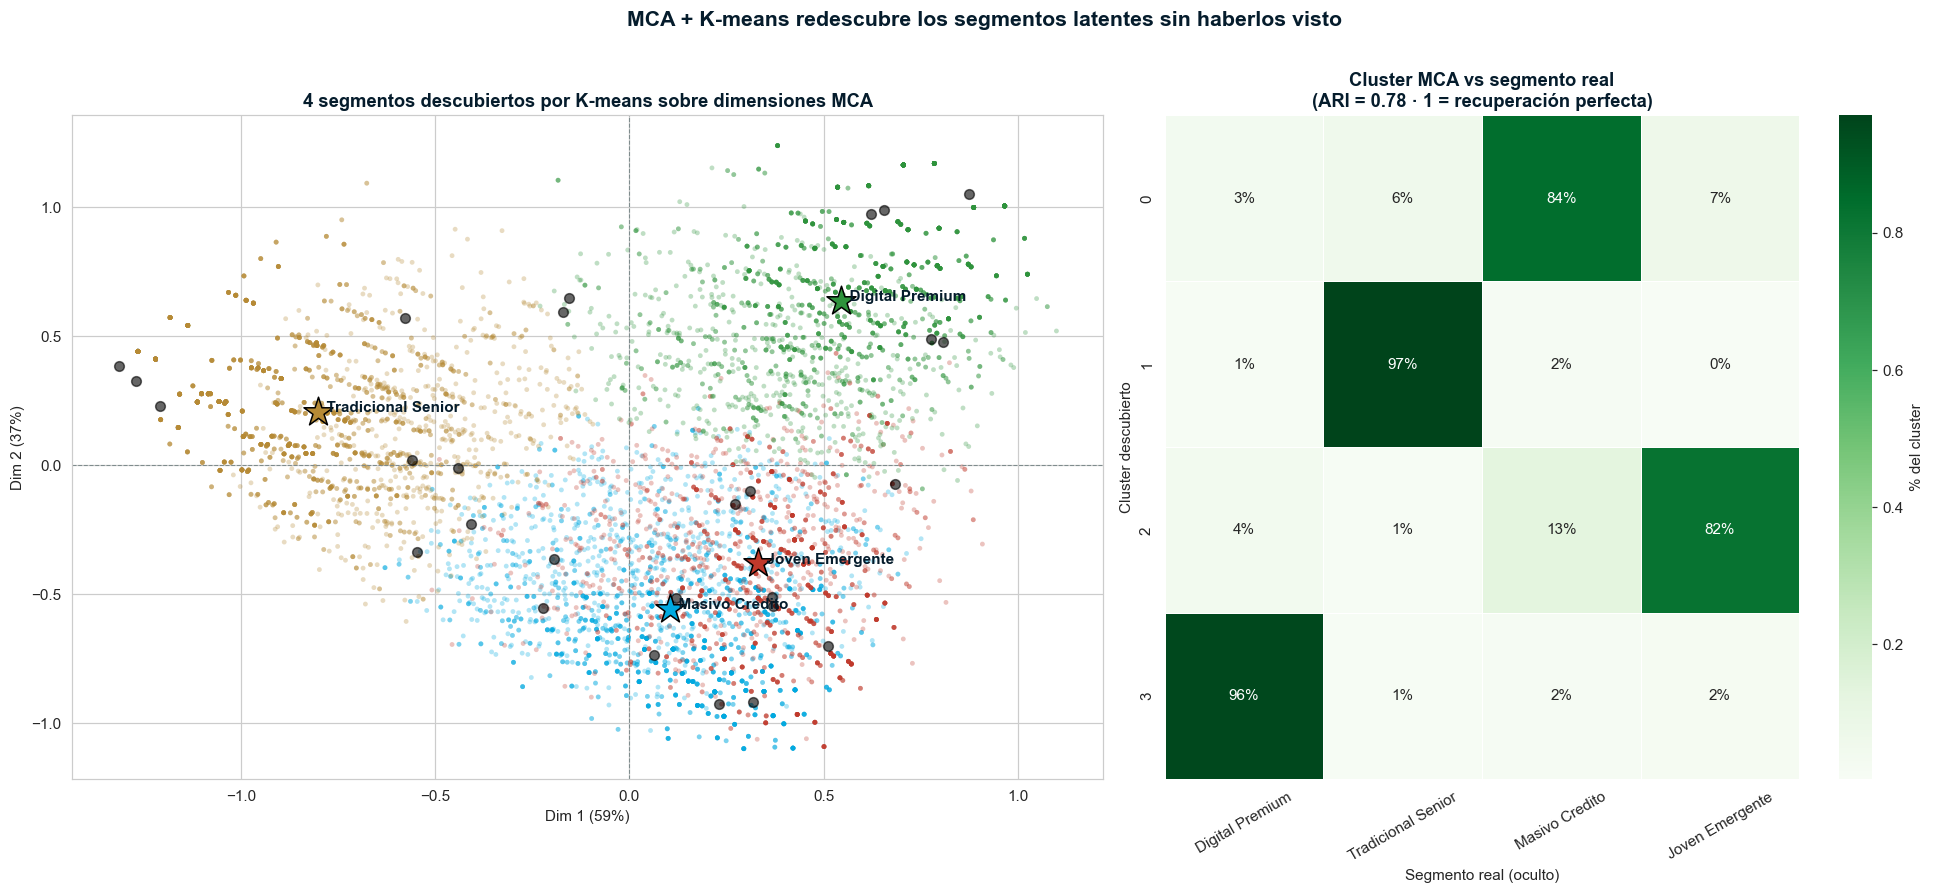

Adjusted Rand Index (concordancia con la verdad oculta): 0.778


In [14]:
n_dims_cluster = 5
km = KMeans(n_clusters=4, n_init=20, random_state=42)
clusters = km.fit_predict(F[:, :n_dims_cluster])

# validación: ¿recuperó MCA+KMeans la estructura latente?
ari = adjusted_rand_score(segmento_real.values, clusters)
tab = pd.crosstab(pd.Series(clusters, name='Cluster MCA'),
                  segmento_real, normalize='index')

# nombre de cada cluster = segmento real dominante
cluster_to_seg = tab.idxmax(axis=1).to_dict()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8),
                               gridspec_kw={'width_ratios':[1.3, 1]})
clu_colors = [TEAL, GOLD, RED, GREEN]
for k in range(4):
    m = clusters == k
    ax1.scatter(F[m, 0], F[m, 1], s=10, color=clu_colors[k], alpha=0.30, edgecolor='none')
    cx, cy = km.cluster_centers_[k, 0], km.cluster_centers_[k, 1]
    ax1.scatter(cx, cy, s=400, color=clu_colors[k], edgecolor='black', marker='*', zorder=6)
    ax1.annotate(f'  {cluster_to_seg[k]}', (cx, cy), fontsize=10, fontweight='bold',
                 color=NAVY, zorder=7)
ax1.scatter(G[:, 0], G[:, 1], s=40, color='black', alpha=0.6, marker='o', zorder=5)
ax1.axhline(0, color=GREY, lw=0.7, ls='--'); ax1.axvline(0, color=GREY, lw=0.7, ls='--')
ax1.set_title('4 segmentos descubiertos por K-means sobre dimensiones MCA', fontsize=12)
ax1.set_xlabel(f'Dim 1 ({veb[0]*100:.0f}%)'); ax1.set_ylabel(f'Dim 2 ({veb[1]*100:.0f}%)')

sns.heatmap(tab[seg_names], annot=True, fmt='.0%', cmap='Greens', ax=ax2,
            cbar_kws={'label':'% del cluster'}, linewidths=.5, linecolor='white')
ax2.set_title(f'Cluster MCA vs segmento real\n(ARI = {ari:.2f} · 1 = recuperación perfecta)',
              fontsize=12)
ax2.set_xlabel('Segmento real (oculto)'); ax2.set_ylabel('Cluster descubierto')
ax2.tick_params(axis='x', rotation=30)
fig.suptitle('MCA + K-means redescubre los segmentos latentes sin haberlos visto',
             fontsize=14, fontweight='bold', color=NAVY, y=1.01)
plt.tight_layout()
plt.savefig(f'{FIGDIR}/10_segmentacion.png', dpi=130)
plt.show()
print(f'Adjusted Rand Index (concordancia con la verdad oculta): {ari:.3f}')

In [15]:
# Perfil de negocio de cada cluster: categoría modal por variable
df_c = df.copy(); df_c['Cluster'] = clusters
print('PERFIL DE CADA SEGMENTO DESCUBIERTO (categoría dominante por variable)\n')
perfil = {}
for k in range(4):
    sub = df_c[df_c['Cluster'] == k]
    fila = {var: sub[var].value_counts().idxmax() for var in variables}
    perfil[f'C{k} · {cluster_to_seg[k]}  (n={len(sub)})'] = fila
perfil_df = pd.DataFrame(perfil).T
perfil_df

PERFIL DE CADA SEGMENTO DESCUBIERTO (categoría dominante por variable)



,Edad,Canal,Tarjeta,Ingreso,FrecDigital,Producto,Antiguedad,Riesgo
C0 · Masivo Credito (n=2405),Adulto,Web,Clasica,Medio,Media,Credito,Establecido,RiesgoMedio
C1 · Tradicional Senior (n=2581),Senior,Sucursal,Clasica,Medio,Nula,Ahorro,Leal,RiesgoBajo
C2 · Joven Emergente (n=1711),Joven,App,SinTarjeta,Bajo,Alta,Ahorro,Nuevo,RiesgoMedio
C3 · Digital Premium (n=2303),Adulto,App,Premium,Alto,Alta,Inversion,Leal,RiesgoBajo


---
## 11. Interpretación de Negocio — del mapa a la acción comercial

Reuniendo todo (mapa de categorías + CTR + clusters), traducimos los ejes a lenguaje de negocio.
**Esta es la razón de ser del MCA: una herramienta interpretativa, no predictiva.**

### Los dos ejes del negocio

| Eje | Lo que define (vía CTR, ver paso 8) | Lectura comercial |
|---|---|---|
| **Dimensión 1** | Sucursal · Senior · Nula · Leal *(−)*  ⟷  App · Premium · Alto · Alta *(+)* | **Madurez digital y de valor**: tradicional-presencial ⟷ digital-activo |
| **Dimensión 2** | Crédito · RiesgoAlto · Bajo · Nuevo *(−)*  ⟷  Premium · Alto · Inversión · RiesgoBajo *(+)* | **Patrimonio y perfil de riesgo**: apalancado/entrante ⟷ patrimonial/seguro |

### Recomendaciones por segmento

In [16]:
recos = {
 'Digital Premium':    ('Retención de alto valor',
    'Cross-sell de inversión/gestión patrimonial vía App. Programa de fidelización premium. '
    'Coste de servir bajo (canal digital) → margen alto: proteger del churn.'),
 'Tradicional Senior': ('Digitalización asistida + protección',
    'Migración suave a canales digitales (onboarding en sucursal). Productos de ahorro/renta. '
    'Alta lealtad y bajo riesgo: base estable, no saturar con campañas.'),
 'Masivo Credito':     ('Gestión de riesgo y rentabilización',
    'Foco en riesgo (RiesgoMedio/Alto). Ofertas de consolidación de deuda. Canales Web/CallCenter. '
    'Upgrade selectivo a tarjeta según comportamiento de pago.'),
 'Joven Emergente':    ('Captación y construcción de relación',
    'Productos de entrada (tarjeta clásica, ahorro). Engagement vía App. Bajo ingreso hoy, '
    'pero alto potencial: nutrir el ciclo de vida hacia Digital Premium.'),
}
print('='*78)
for k in range(4):
    seg = cluster_to_seg[k]
    titulo, accion = recos[seg]
    n_seg = (clusters == k).sum()
    print(f'▶ CLUSTER {k} · {seg}  ({n_seg} clientes, {n_seg/N*100:.0f}%)')
    print(f'  Estrategia: {titulo}')
    print(f'  Acción    : {accion}')
    print('='*78)

▶ CLUSTER 0 · Masivo Credito  (2405 clientes, 27%)
  Estrategia: Gestión de riesgo y rentabilización
  Acción    : Foco en riesgo (RiesgoMedio/Alto). Ofertas de consolidación de deuda. Canales Web/CallCenter. Upgrade selectivo a tarjeta según comportamiento de pago.
▶ CLUSTER 1 · Tradicional Senior  (2581 clientes, 29%)
  Estrategia: Digitalización asistida + protección
  Acción    : Migración suave a canales digitales (onboarding en sucursal). Productos de ahorro/renta. Alta lealtad y bajo riesgo: base estable, no saturar con campañas.
▶ CLUSTER 2 · Joven Emergente  (1711 clientes, 19%)
  Estrategia: Captación y construcción de relación
  Acción    : Productos de entrada (tarjeta clásica, ahorro). Engagement vía App. Bajo ingreso hoy, pero alto potencial: nutrir el ciclo de vida hacia Digital Premium.
▶ CLUSTER 3 · Digital Premium  (2303 clientes, 26%)
  Estrategia: Retención de alto valor
  Acción    : Cross-sell de inversión/gestión patrimonial vía App. Programa de fidelización prem

---
## 12. Dashboard Final — Resumen Visual Integrado

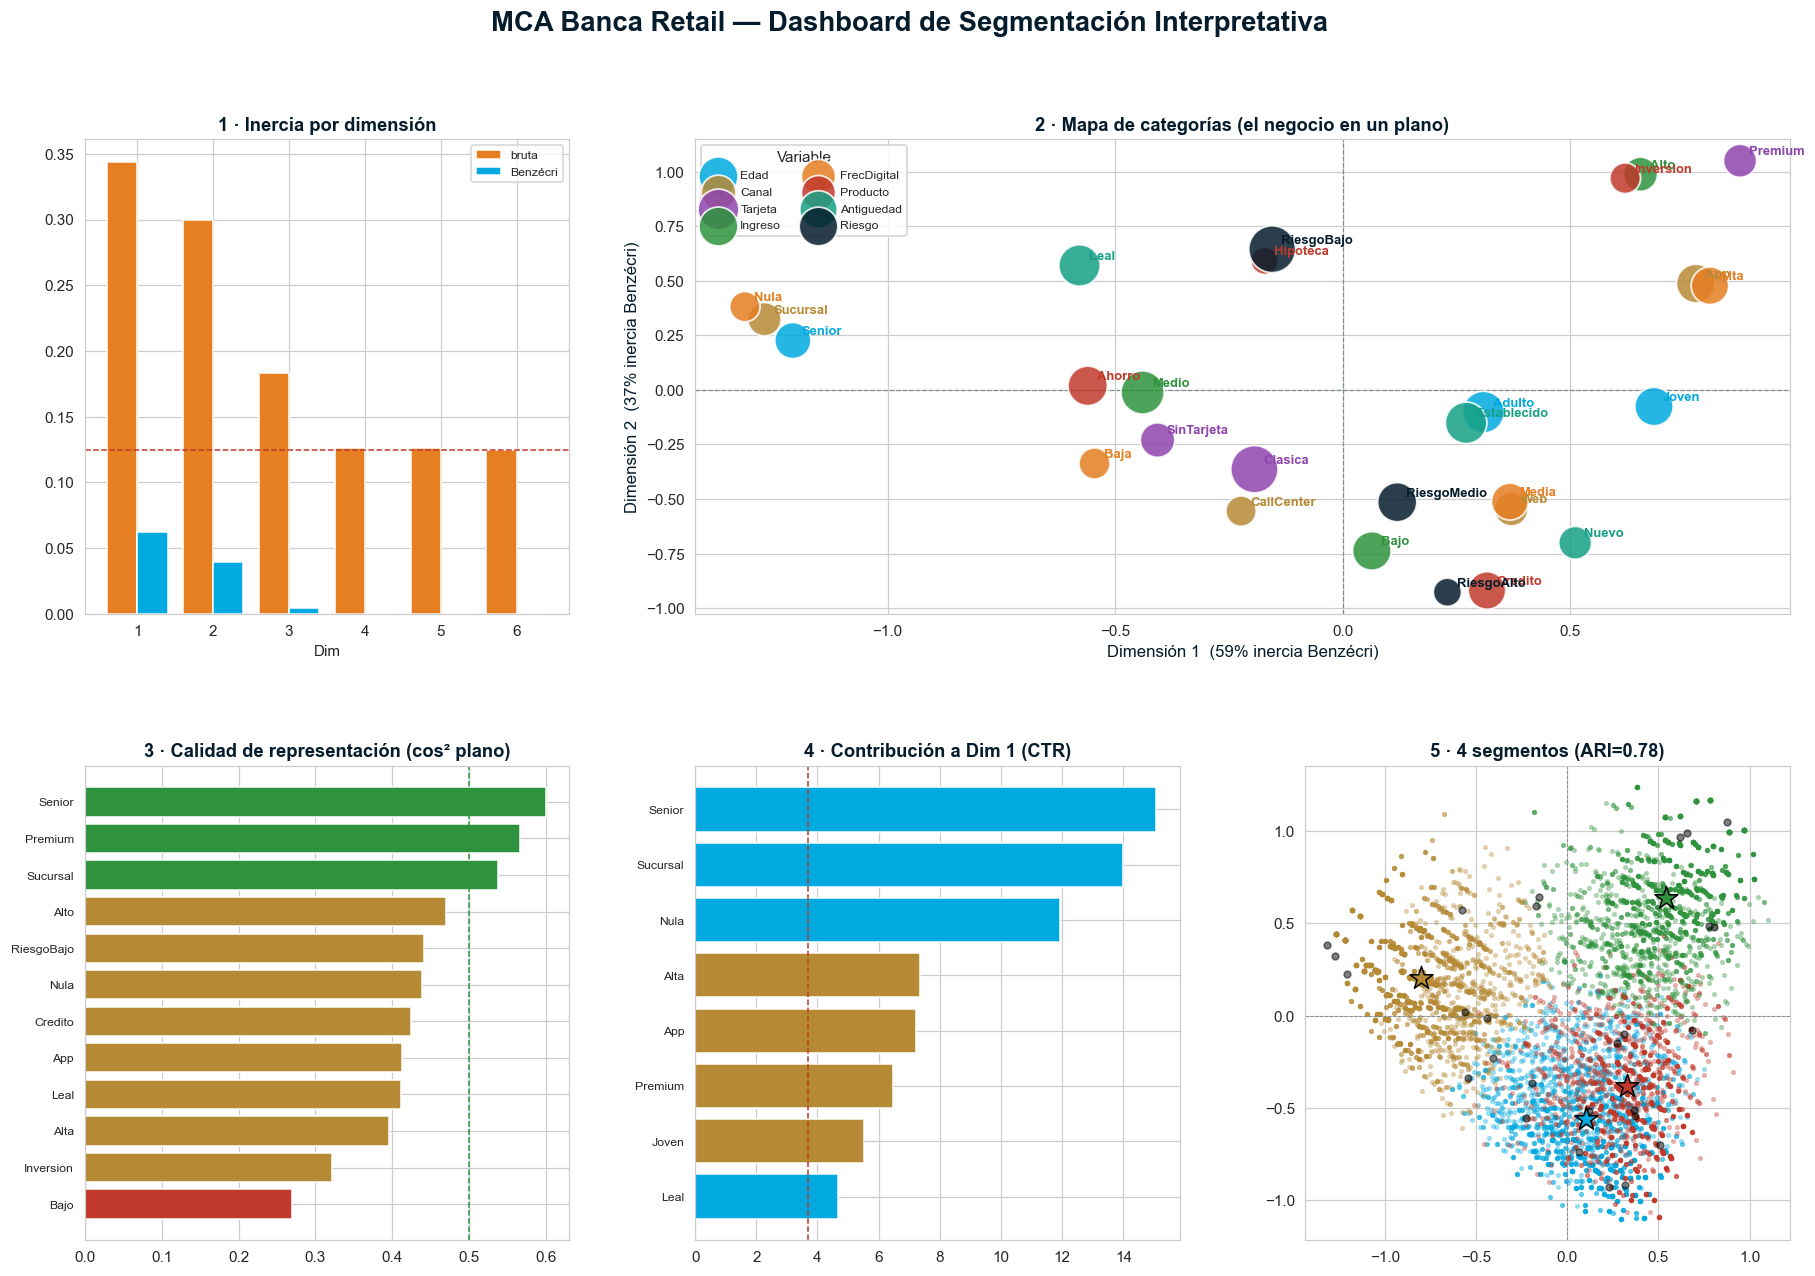

In [17]:
fig = plt.figure(figsize=(20, 13))
gs = fig.add_gridspec(2, 3, hspace=0.32, wspace=0.26)

# (1) scree Benzécri
axA = fig.add_subplot(gs[0, 0])
xx = np.arange(1, 7)
axA.bar(xx-0.2, lam[:6], 0.4, color=ORANGE, label='bruta')
axA.bar(xx+0.2, lam_b[:6], 0.4, color=TEAL, label='Benzécri')
axA.axhline(1/Q, color=RED, ls='--', lw=1)
axA.set_title('1 · Inercia por dimensión'); axA.set_xlabel('Dim'); axA.legend(fontsize=8)

# (2) mapa de categorías (reusa función)
axB = fig.add_subplot(gs[0, 1:])
biplot_categorias(axB)
axB.set_title('2 · Mapa de categorías (el negocio en un plano)')

# (3) cos2 plano
axC = fig.add_subplot(gs[1, 0])
order = np.argsort(cos2_plane)[::-1][:12]
cols = [GREEN if cos2_plane[i]>=0.5 else (GOLD if cos2_plane[i]>=0.3 else RED) for i in order]
axC.barh(range(len(order)), cos2_plane[order], color=cols, edgecolor='white')
axC.set_yticks(range(len(order))); axC.set_yticklabels([cat_lab[i] for i in order], fontsize=8)
axC.invert_yaxis(); axC.axvline(0.5, color=GREEN, ls='--', lw=1)
axC.set_title('3 · Calidad de representación (cos² plano)')

# (4) CTR dim1
axD = fig.add_subplot(gs[1, 1])
o1 = np.argsort(CTR[:,0])[::-1][:8]
axD.barh(range(len(o1)), CTR[o1,0]*100,
         color=[TEAL if G[i,0]<0 else GOLD for i in o1], edgecolor='white')
axD.set_yticks(range(len(o1))); axD.set_yticklabels([cat_lab[i] for i in o1], fontsize=8)
axD.invert_yaxis(); axD.axvline(1/J*100, color=RED, ls='--', lw=1)
axD.set_title('4 · Contribución a Dim 1 (CTR)')

# (5) segmentos
axE = fig.add_subplot(gs[1, 2])
for k in range(4):
    m = clusters==k
    axE.scatter(F[m,0], F[m,1], s=6, color=clu_colors[k], alpha=0.3)
    axE.scatter(km.cluster_centers_[k,0], km.cluster_centers_[k,1], s=250,
                color=clu_colors[k], marker='*', edgecolor='black', zorder=5)
axE.scatter(G[:,0], G[:,1], s=20, color='black', alpha=0.5)
axE.axhline(0, color=GREY, lw=.6, ls='--'); axE.axvline(0, color=GREY, lw=.6, ls='--')
axE.set_title(f'5 · 4 segmentos (ARI={ari:.2f})')

fig.suptitle('MCA Banca Retail — Dashboard de Segmentación Interpretativa',
             fontsize=18, fontweight='bold', color=NAVY, y=0.97)
plt.savefig(f'{FIGDIR}/00_dashboard_final.png', dpi=130)
plt.show()

---
## 13. Conclusiones del Business Case

### Lo que MCA nos dio (y PCA no podía)

1. **Un mapa interpretable de variables categóricas.** Convertimos 28 tablas de contingencia
   cruzadas en **un único plano** donde las asociaciones se leen a simple vista.
2. **Ejes con nombre de negocio.** Vía **CTR** nombramos las dimensiones: *madurez digital/valor*
   (Dim 1) y *ciclo de vida* (Dim 2).
3. **Honestidad estadística.** El **cos²** nos dijo de qué categorías fiarnos en el mapa; la
   **corrección de Benzécri** convirtió un engañoso ~22% en un ~80% de inercia real explicada.
4. **Segmentación accionable.** K-means sobre las dimensiones MCA **redescubrió los 4 segmentos
   latentes** (ARI alto) sin haberlos visto nunca — y cada uno trae su estrategia comercial.

### Las 5 reglas de oro del MCA (para llevar a casa)

| # | Regla |
|---|---|
| 1 | La **inercia total** $(J-Q)/Q$ es fija: lo interesante es **cómo se reparte** entre ejes. |
| 2 | **Siempre** reporta varianza explicada con **Benzécri** (sin ella, parece un fracaso). |
| 3 | **Proximidad en el mapa = coexistencia** en los mismos clientes (distancia χ², no euclídea). |
| 4 | Verifica **cos²** antes de interpretar: una categoría rara y lejana puede no ser fiable. |
| 5 | Usa **CTR** para *nombrar* los ejes; usa el **mapa + clusters** para *contar la historia*. |

### El mensaje para la clase

> MCA no predice: **interpreta**. Donde antes había decenas de tablas cruzadas inmanejables, ahora
> hay un mapa donde el negocio se lee de un vistazo. Esa es su superpotencia.

---

### Artefactos generados

- `dataset_banca_mca_9k.csv` — dataset categórico (9.000 clientes)
- `00_dashboard_final.png` … `10_segmentacion.png` — figuras del caso

In [18]:
# Exportamos los scores MCA y la asignación de cluster para uso posterior
out = df.copy()
for d in range(5):
    out[f'MCA_Dim{d+1}'] = F[:, d]
out['Cluster'] = clusters
out['Segmento_descubierto'] = [cluster_to_seg[k] for k in clusters]
out['Segmento_real'] = segmento_real.values
out.to_csv('clientes_banca_mca_scores.csv', index=False, encoding='utf-8')
print('Guardado: clientes_banca_mca_scores.csv  ·', out.shape)
print('\n✅ Business Case MCA completo.')

Guardado: clientes_banca_mca_scores.csv  · (9000, 16)

✅ Business Case MCA completo.
